In [1]:
import pytorch_lightning as pl
import mlflow
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

In [2]:
emnist_train_data = pd.read_csv("./emnist-letters-train.csv", header=None)
emnist_test_data = pd.read_csv("./emnist-letters-test.csv", header=None)

emnist_test_data = emnist_test_data.sample(frac = 1) #shuffles the data

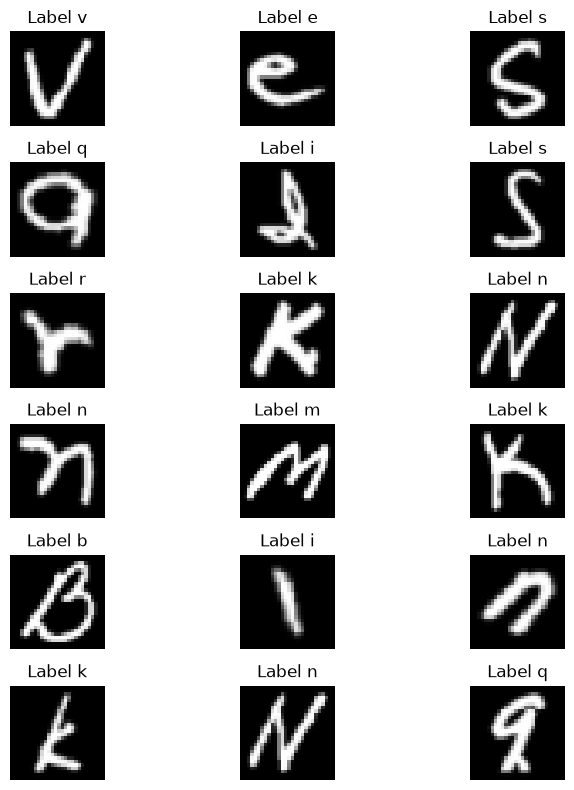

In [3]:
classes = list("abcdefghijklmnopqrstuvwxyz")

train_labels = emnist_train_data.values[:, 0]
train_images = emnist_train_data.values[:, 1:]

train_images = train_images.reshape(-1, 28, 28)

num_samples = 18

random_indices = np.random.randint(0, len(train_images), num_samples)

random_indices

fig = plt.figure(figsize= (8, 8))
for i, idx in enumerate(random_indices):
  plt.subplot(6, int(num_samples / 6), i+1)
  plt.imshow(train_images[idx].T /255.0, cmap="gray")
  plt.title(f'Label {classes[int(train_labels[idx]-1)]}')
  plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:
class EMNISTDataset(Dataset):
  def __init__(self, dataframe):
    self.images = torch.tensor(dataframe.iloc[:,1:].values, dtype=torch.float32)
    self.labels = torch.tensor(dataframe.iloc[:,0].values, dtype=torch.float32)

  def __len__(self):
    return len(self.images)

  def __getitem__(self, idx):
    images = self.images[idx]
    images = images/255.0
    labels = self.labels[idx]

    return images, labels

In [5]:
test_dataset = EMNISTDataset(emnist_test_data)

test_dataloader = DataLoader(test_dataset, batch_size=64)

In [6]:
test_dataiter = iter(test_dataloader)

test_imgs, test_labels = next(test_dataiter)

test_imgs.shape, test_labels.shape

(torch.Size([64, 784]), torch.Size([64]))

In [7]:
#experiment_id = mlflow.create_experiment(name = 'test_experiment')

#experiment_id

In [8]:
#see experiments in mlflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')

print("______MLFlow experiments______")
experiments = mlflow.search_experiments()
if not experiments:
  print("No MLflow experiments found.")
for exp in experiments:
  print(f'Experiment ID: {exp.experiment_id}, Name: {exp.name}, Artifact Location: {exp.artifact_location}')
print('-'*24)

______MLFlow experiments______
Experiment ID: 3, Name: emnist_letters_prediction_cnn_lion_variants, Artifact Location: file:///<home>/Jupyter_AI/mlflow/mlruns/3
Experiment ID: 2, Name: test_experiment, Artifact Location: file:///<home>/Jupyter_AI/mlflow/mlruns/2
Experiment ID: 1, Name: EMNIST, Artifact Location: mlflow-artifacts:/1
------------------------


In [9]:
from mlflow.models import ModelSignature
from mlflow.types import Schema, TensorSpec


signature = ModelSignature(
    inputs=Schema([
        TensorSpec(
            np.dtype(np.float32),
            (-1, 1, 28, 28),
        )
    ]),
    outputs=Schema([
        TensorSpec(
            np.dtype(np.float32),
            (-1, 26),
        )
    ]),
)

print(signature)

inputs: 
  [Tensor('float32', (-1, 1, 28, 28))]
outputs: 
  [Tensor('float32', (-1, 26))]
params: 
  None



In [10]:
train_dataset = EMNISTDataset(emnist_train_data)
test_dataset = EMNISTDataset(emnist_test_data)

len(train_dataset), len(test_dataset)

(88800, 14800)

In [11]:
from torch.utils.data import random_split

val_percent = 0.1
val_len = int(val_percent* len(train_dataset))

train_ds, val_ds =random_split(train_dataset, [len(train_dataset) - val_len, val_len])

print(len(train_ds), len(val_ds))

79920 8880


In [19]:
batch_size = 64

train_dataloader = DataLoader(train_ds, batch_size, shuffle=True, drop_last=True, num_workers=0)

val_dataloader = DataLoader(val_ds, batch_size, num_workers=0)

test_dataloader = DataLoader(test_dataset, batch_size, num_workers=0)

len(train_dataloader),len(val_dataloader),len(test_dataloader)

(1248, 139, 232)

In [20]:
#setting up the experiement for our CNN
exp_name = "emnist_letters_prediction_cnn_lion_variants"

#only need to do this the first time
#experiment_id = mlflow.create_experiment(name = exp_name)
mlflow.set_experiment(experiment_name = exp_name)

<Experiment: artifact_location='file:///<home>/Jupyter_AI/mlflow/mlruns/3', creation_time=1785346460440, effective_trace_archival_retention=None, experiment_id='3', last_update_time=1785346460440, lifecycle_stage='active', name='emnist_letters_prediction_cnn_lion_variants', tags={}, trace_location=None, workspace='default'>

In [21]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import pytorch_lightning as pl

from torchmetrics.functional import accuracy

input_size = 28*28
output_size = 26

In [51]:
import sys
import os
import importlib

sys.path.insert(0, os.path.abspath("../optimizers"))

import lion_deadzone

importlib.reload(lion_deadzone)

Lion = lion_deadzone.Lion

In [52]:
class EmnistModel(pl.LightningModule):
  def __init__(self, lr = 1e-5, deadzone = 0.0):
    super().__init__()

    self.lr = lr
    self.deadzone = deadzone
      
    self.criterion = nn.CrossEntropyLoss()

    self.net = nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.MaxPool2d(2,2), # (64, 14, 14)

        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.LeakyReLU(0.1),
        nn.MaxPool2d(2,2), # (256, 7, 7)

        nn.Flatten(),
        nn.Linear(256*7*7, 32),
        nn.LeakyReLU(0.1),
        nn.Linear(32, 64),
        nn.LeakyReLU(0.1),

        nn.Linear(64, 26)
    )

    

  def forward(self, xb):
    out = self.net(xb.reshape(-1, 1, 28, 28))
    return out

  def configure_optimizers(self):
    return Lion(self.parameters(), lr = self.lr, deadzone = self.deadzone)

  def training_step(self, batch, batch_idx):
    x, y = batch
    y -= 1

    y_hat = self(x)
    loss = self.criterion(y_hat, y.long())
    pred = y_hat.argmax(dim = 1)

    acc = accuracy(pred, y, task = "multiclass", num_classes = 26)

    self.log("train_loss", loss, on_epoch = True, prog_bar = True)
    self.log("train_acc", acc, on_epoch = True, prog_bar = True)

    return loss

  def validation_step(self, batch, batch_idx):
    x, y = batch
    y-=1

    y_hat = self(x)
    loss = self.criterion(y_hat, y.long())
    pred = y_hat.argmax(dim = 1)

    acc = accuracy(pred, y, task = "multiclass", num_classes = 26)

    self.log("val_loss", loss, on_epoch = True, prog_bar = True)
    self.log("val_acc", acc, on_epoch = True, prog_bar = True)

    return acc

  def test_step(self, batch, batch_idx):
    x, y = batch
    y -= 1

    y_hat = self(x)
    loss = self.criterion(y_hat, y.long())
    pred = y_hat.argmax(dim = 1)

    acc = accuracy(pred, y, task = "multiclass", num_classes = 26)

    self.log("test_loss", loss, on_epoch = True, prog_bar = True)
    self.log("test_acc", acc, on_epoch = True, prog_bar = True)

    return acc

  def optimizer_step(
    self,
    epoch,
    batch_idx,
    optimizer,
    optimizer_closure
  ):
    optimizer.step(closure=optimizer_closure)

    raw_optimizer = optimizer.optimizer

    if raw_optimizer.active_fraction is not None:
        self.log(
            "train/active_fraction",
            raw_optimizer.active_fraction,
            on_step=True,
            on_epoch=True,
            prog_bar=True
        )

  def predict_step(self, batch, batch_idx, dataloader_idx = 0):
    x, y = batch

    return self(x)

In [55]:
from mlflow.models.signature import ModelSignature
from mlflow.types.schema import ColSpec, Schema, TensorSpec
from pytorch_lightning.loggers import CSVLogger

def train_model_dz(deadzone = 0.0):
    emnist_model = EmnistModel(lr = 1e-4, deadzone=deadzone)
    
    
    logger = CSVLogger("logs", name = "emnist_letters_classifier_lion_test_2")
    
    trainer = pl.Trainer(max_epochs = 10, logger = logger)
    
    mlflow.pytorch.autolog(log_models = False) #auto log everything except for models
    
    with mlflow.start_run() as run:
      trainer.fit(emnist_model, train_dataloader, val_dataloader)
      trainer.test(dataloaders = test_dataloader)
    
      input_schema = Schema([TensorSpec(np.dtype(np.float32), (-1, 1, 28, 28))])
      output_schema = Schema([TensorSpec(np.dtype(np.float32), (-1, 26))])
    
      signature = ModelSignature(inputs = input_schema, outputs = output_schema)
    
    
      
      input_example = torch.stack([
        train_ds[0][0],
        train_ds[1][0],
      ]).float().cpu()
        
      mlflow.pytorch.log_model(emnist_model, 
                               name = "emnist-letters-classifier-cnn-model-test_2", 
                               signature = signature,
                               input_example = input_example)

deadzones = [0.0,
    1e-8, 3e-8,
    1e-7, 3e-7,
    1e-6, 3e-6,]

for dz in deadzones:
    train_model_dz(dz)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type             | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | criterion | CrossEntropyLoss | 0      | train | 0    
1 | net       | Sequential       | 793 K  | train | 0    
---------------------------------------------------------------
793 K     Trainable params
0         Non-trainable params
793 K     Total params
3.172     Total estimated model params size (MB)
18        

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

<home>\miniconda3\envs\micrograd\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
<home>\miniconda3\envs\micrograd\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (110 outputs left out)

`Trainer.fit` stopped: `max_epochs=10` reached.
<home>\miniconda3\envs\micrograd\Lib\site-packages\pytorch_lightning\trainer\connectors\checkpoint_connector.py:149: `.test(ckpt_path=None)` was called without a model. The best model of the previous `fit` call will be used. You can pass `.test(ckpt_path='best')` to use the best model or `.test(ckpt_path='last')` to use the last model. If you pass a value, this warning will be silenced.
Restoring states from the checkpoint path at logs\emnist_letters_classifier_lion_test_2\version_9\checkpoints\epoch=9-step=12480.ckpt
<home>\miniconda3\envs\micrograd\Lib\site-packages\lightning_fabric\utilities\cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In 

Testing: |          | 0/? [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc             0.926756739616394
        test_loss            0.261852890253067
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


2026/07/29 15:22:52 WARNING mlflow.utils.requirements_utils: Found torch version (2.5.1+cu121) contains a local version label (+cu121). MLflow logged a pip requirement for this package as 'torch==2.5.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/07/29 15:23:01 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: <home>\AppData\Local\Temp\tmpvg5q7jlh\model\data, flavor: pytorch). Fall back to return ['torch==2.5.1', 'cloudpickle==3.1.2']. Set logging level to DEBUG to see the full traceback. 


In [ ]:
metrics = pd.read_csv(f'{trainer.logger.log_dir}/metrics.csv')

metrics

In [49]:
 train_ds[0][0].view((-1, 1, 28, 28)).detach().cpu().shape

torch.Size([1, 1, 28, 28])